## Importação e Início

In [1]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
plt.style.use('ggplot')

In [ ]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
gdown.download(url=url, output=output, quiet=False)

In [2]:
df = pd.read_json('filmes.json', orient='records')

### Retirada de Outliers

In [3]:
df = df[
    (df['roi'] < 30000) &
    (df['budget'] > 1000) &
    (df['vote_count'] > 50)
].copy()

## Mês e dia da Semana

In [4]:
# Conversão das datas e criação das variáveis de sazonalidade
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_month'] = df['release_date'].dt.month
df['release_day_name'] = df['release_date'].dt.day_name()

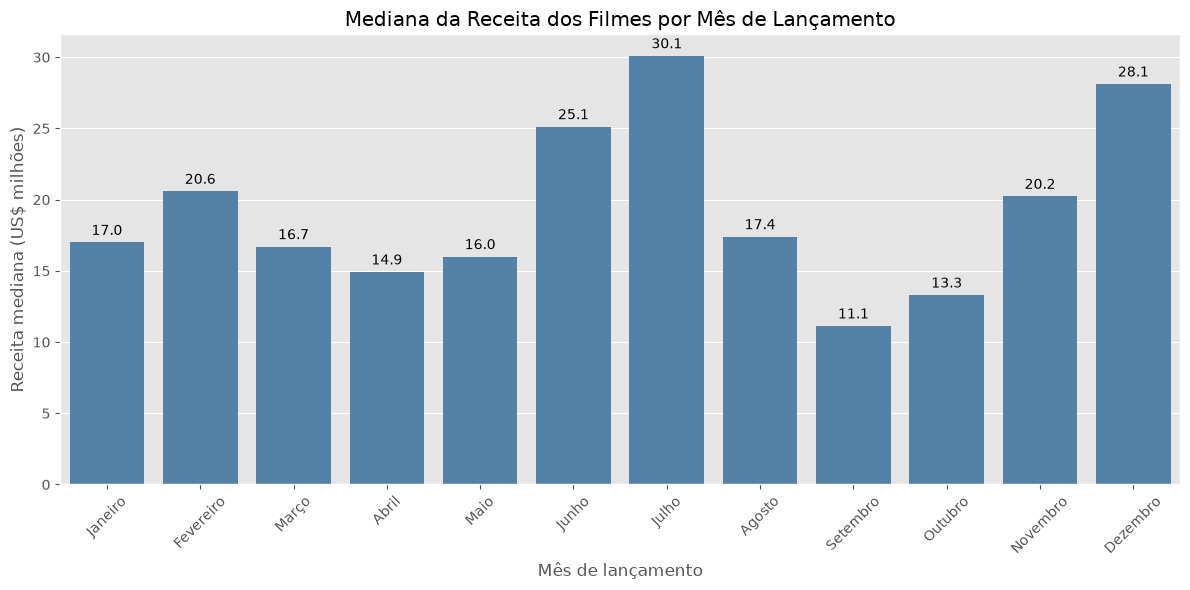

In [6]:
meses = [
    'Janeiro', 'Fevereiro', 'Março', 'Abril',
    'Maio', 'Junho', 'Julho', 'Agosto',
    'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]

receita_mediana_por_mes = (
    df.dropna(subset=['release_month', 'revenue'])
      .groupby('release_month')['revenue']
      .median()
      .reindex(range(1, 13))
      .div(1_000_000)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=meses,
    y=receita_mediana_por_mes.values,
    color='steelblue'
)

ax.set_title('Mediana da Receita dos Filmes por Mês de Lançamento')
ax.set_xlabel('Mês de lançamento')
ax.set_ylabel('Receita mediana (US$ milhões)')
ax.tick_params(axis='x', rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

O Mês de Lançamento impacta no sucesso financeiro do Filme

### Receita por dia da semana

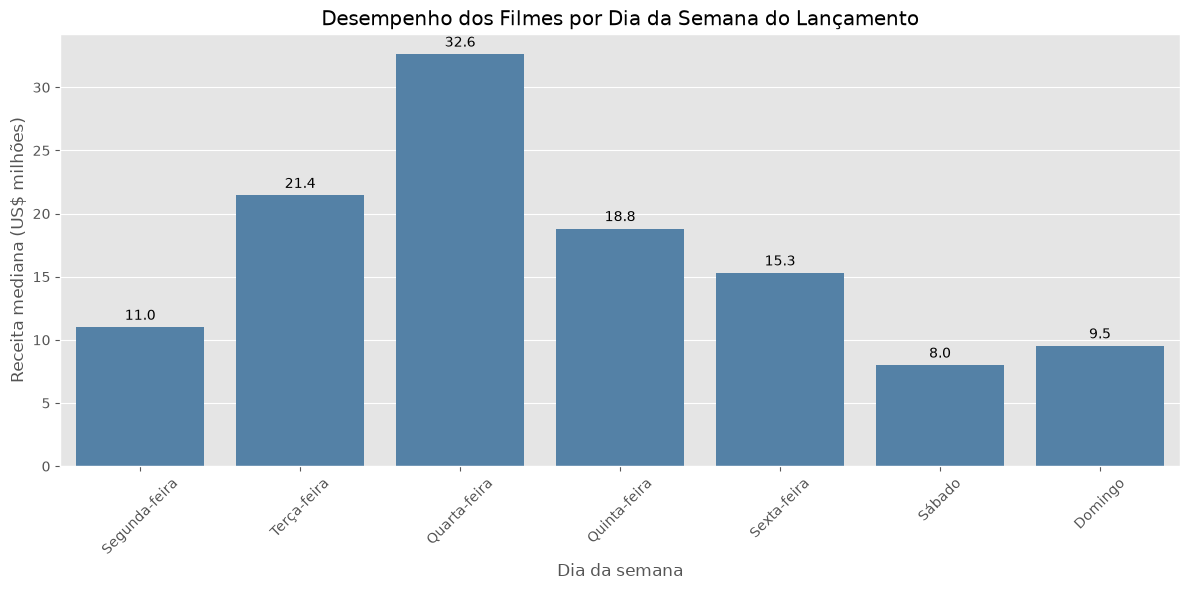

In [7]:
dias_pt = {
    'Monday': 'Segunda-feira',
    'Tuesday': 'Terça-feira',
    'Wednesday': 'Quarta-feira',
    'Thursday': 'Quinta-feira',
    'Friday': 'Sexta-feira',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_performance = (
    df.dropna(subset=['release_day_name', 'revenue'])
      .groupby('release_day_name', as_index=False)['revenue']
      .median()
      .rename(columns={'revenue': 'receita_mediana_milhoes'})
)

day_performance['receita_mediana_milhoes'] /= 1_000_000
day_performance['dia_semana'] = day_performance['release_day_name'].map(dias_pt)

ordem_pt = [dias_pt[dia] for dia in day_order]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=day_performance,
    x='dia_semana',
    y='receita_mediana_milhoes',
    order=ordem_pt,
    color='steelblue'
)

ax.set_title('Desempenho dos Filmes por Dia da Semana do Lançamento')
ax.set_xlabel('Dia da semana')
ax.set_ylabel('Receita mediana (US$ milhões)')
ax.tick_params(axis='x', rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()


Conclusão: O dia da semana impacta no sucesso financeiro do Filme

### Empresas

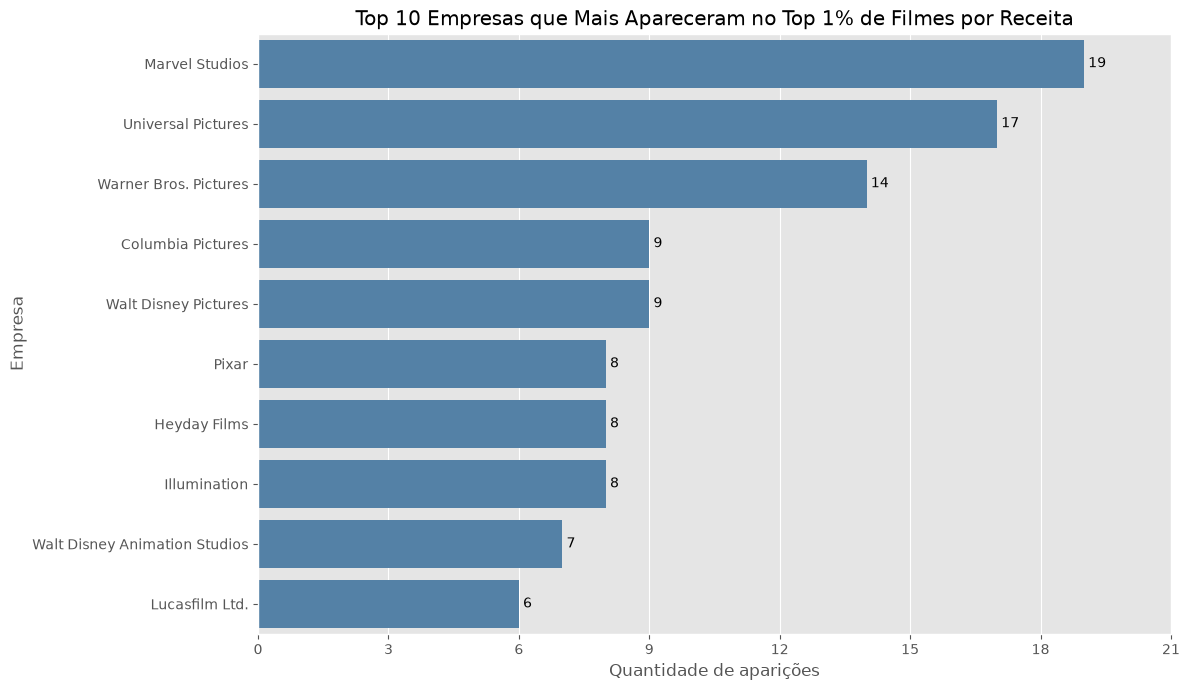

In [9]:
# Seleciona o 1% de filmes com maior receita
quantidade_top_1pct = max(1, int(np.ceil(len(df) * 0.01)))

top_1pct = (
    df.nlargest(quantidade_top_1pct, 'revenue')
      .copy()
)

# Identifica sequências por coleção
top_1pct_com_sequencia = top_1pct.copy()
top_1pct_com_sequencia['eh_sequencia'] = (
    top_1pct_com_sequencia['belongs_to_collection']
    .apply(lambda x: isinstance(x, dict) and bool(x.get('id')))
)

# Conta as produtoras presentes nos filmes do top 1%
companies = (
    top_1pct['production_companies']
    .apply(lambda companies: [
        company.get('name')
        for company in companies
        if isinstance(company, dict) and company.get('name')
    ])
    .explode()
    .dropna()
)

contagem_companies_top_1pct = (
    companies.value_counts()
    .rename_axis('company')
    .reset_index(name='quantidade')
)

top_10_companies = (
    contagem_companies_top_1pct
    .nlargest(10, 'quantidade')
    .sort_values('quantidade', ascending=False)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_companies,
    x='quantidade',
    y='company',
    color='steelblue'
)

ax.set_title('Top 10 Empresas que Mais Apareceram no Top 1% de Filmes por Receita')
ax.set_xlabel('Quantidade de aparições')
ax.set_ylabel('Empresa')
ax.set_xlim(0, top_10_companies['quantidade'].max() + 2)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


Filmes de Sucesso tendem a ser de grandes produtoras.

### Orçamento

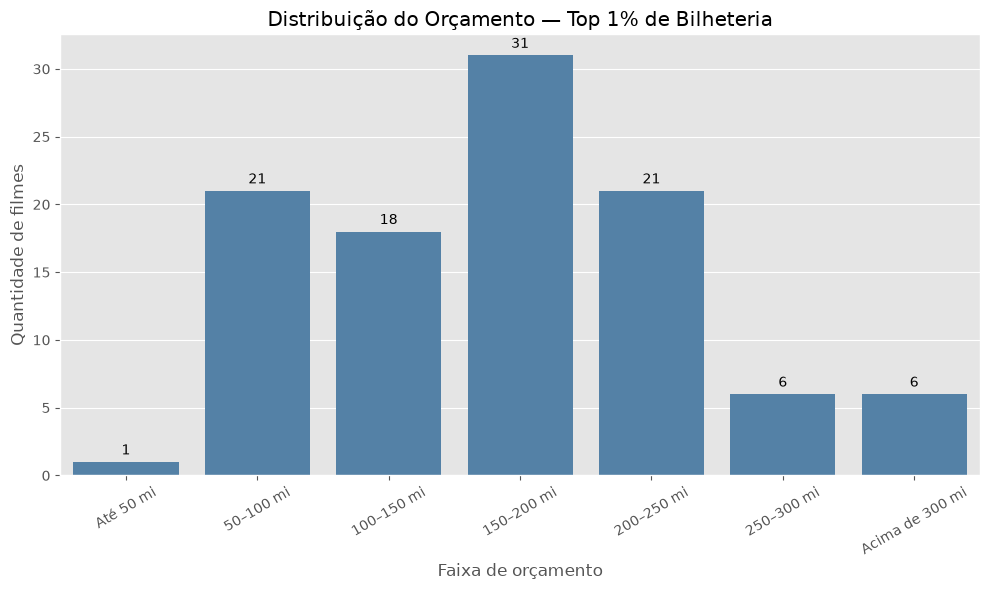

In [19]:
# Agrupa o orçamento do Top 1% em faixas de US$ milhões
faixas_orcamento = [0, 50, 100, 150, 200, 250, 300, np.inf]
rotulos_orcamento = [
    'Até 50 mi',
    '50–100 mi',
    '100–150 mi',
    '150–200 mi',
    '200–250 mi',
    '250–300 mi',
    'Acima de 300 mi'
]

orcamento_agrupado = (
    pd.cut(
        top_1pct['budget'] / 1_000_000,
        bins=faixas_orcamento,
        labels=rotulos_orcamento,
        include_lowest=True
    )
    .value_counts()
    .reindex(rotulos_orcamento, fill_value=0)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=orcamento_agrupado.index,
    y=orcamento_agrupado.values,
    color='steelblue'
)

ax.set_title('Distribuição do Orçamento — Top 1% de Bilheteria')
ax.set_xlabel('Faixa de orçamento')
ax.set_ylabel('Quantidade de filmes')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
mediana_budget_top_1pct = top_1pct['budget'].median()

print(f"Mediana do orçamento do Top 1%: US$ {mediana_budget_top_1pct:,.2f}")
mediana_budget = df['budget'].median()

print(f"Mediana do orçamento: US$ {mediana_budget:,.2f}")

Mediana do orçamento: US$ 12,500,000.00


### Sequências

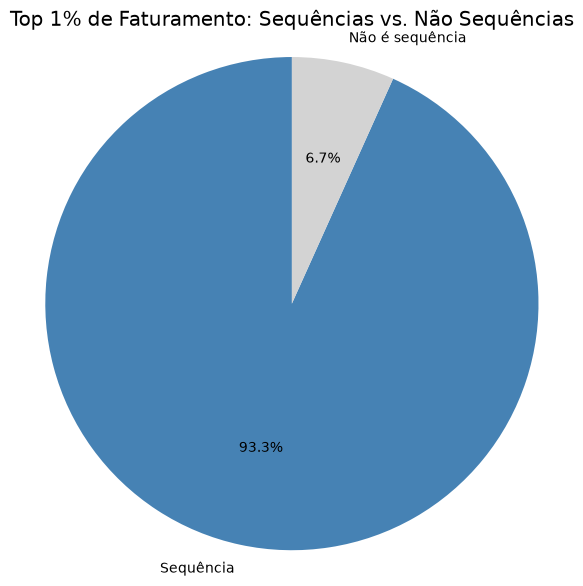

In [10]:
contagem_sequencias = (
    top_1pct_com_sequencia['eh_sequencia']
    .map({True: 'Sequência', False: 'Não é sequência'})
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(
    contagem_sequencias.values,
    labels=contagem_sequencias.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['steelblue', 'lightgray']
)

plt.title('Top 1% de Faturamento: Sequências vs. Não Sequências')
plt.axis('equal')
plt.show()

Filmes de Sucesso de Bilheteria tendem a ser Sequências